In [1]:
#1. Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [2]:
#create a sample customer data
df = pd.DataFrame({
    "customer_id": range(1, 16),
    "recency": [5, 8, 10, 12, 7, 30, 35, 40, 45, 38, 70, 75, 80, 85, 90],
    "frequency": [20, 18, 22, 17, 21, 10, 12, 9, 11, 8, 3, 4, 2, 3, 1],
    "monetary": [8000, 7500, 9000, 7200, 8500, 4000, 4500, 3800, 4200, 3500,
                 1000, 1200, 800, 900, 500]
})

df.head()

,customer_id,recency,frequency,monetary
0,1,5,20,8000
1,2,8,18,7500
2,3,10,22,9000
3,4,12,17,7200
4,5,7,21,8500


In [3]:
print("Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Shape: (15, 4)

Data Types:
customer_id    int64
recency        int64
frequency      int64
monetary       int64
dtype: object

Missing Values:
customer_id    0
recency        0
frequency      0
monetary       0
dtype: int64

Duplicate Rows: 0


In [4]:
X = df[["recency", "frequency", "monetary"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.23950027  1.30276882  1.24573356]
 [-1.13900025  1.0215957   1.07708732]
 [-1.07200023  1.58394195  1.58302605]
 [-1.00500022  0.88100913  0.97589958]
 [-1.17250025  1.44335539  1.41437981]]


In [5]:
#apply k-means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df["cluster"] = kmeans.fit_predict(X_scaled)

df[["customer_id", "recency", "frequency", "monetary", "cluster"]]

,customer_id,recency,frequency,monetary,cluster
0,1,5,20,8000,2
1,2,8,18,7500,2
2,3,10,22,9000,2
3,4,12,17,7200,2
4,5,7,21,8500,2
5,6,30,10,4000,0
6,7,35,12,4500,0
7,8,40,9,3800,0
8,9,45,11,4200,0
9,10,38,8,3500,0


In [6]:
#apply pca
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("Total Variance Explained:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.98235891 0.01687496]
Total Variance Explained:
0.9992338735765999


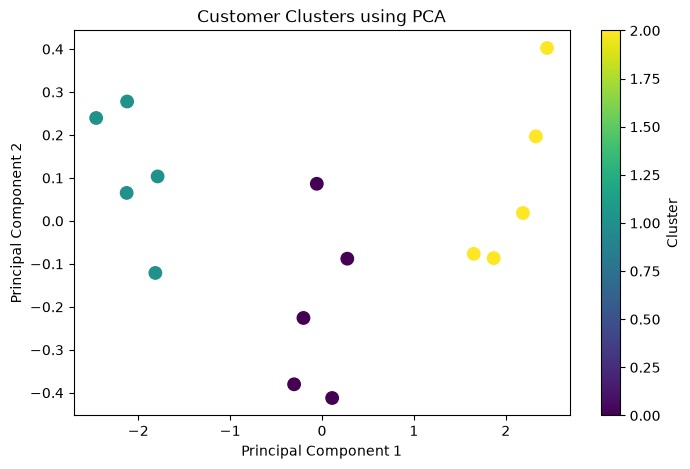

In [7]:
#visualize the clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df["cluster"],
    cmap="viridis",
    s=80
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Clusters using PCA")

plt.colorbar(label="Cluster")
plt.show()

## 8. Explain in Your Own Words

1. What does PCA stand for?
PCA stands for Principal Component Analysis. It is used to reduce the number of features in a dataset.

2. What is dimensionality reduction?
Dimensionality reduction means reducing the number of features while keeping important information from the data.

3. Why do we scale data before applying PCA?
We scale the data to bring all features to a similar range so that larger values do not dominate PCA.

4. What are principal components?
Principal components are new features created by PCA from the original features. They capture important information from the data.

5. What does explained variance ratio tell us?
It tells us how much information each principal component captures from the original data.

6. Why do we use two components for visualization?
We use two components to represent the data in a 2D scatter plot, which makes it easier to visualize.

7. What is the difference between PCA and K-Means?
PCA reduces the number of features, whereas K-Means groups similar data points into clusters.